# Compatibilidad de outfits

EDA del catálogo (500 prendas), de los 100.000 outfits y de un test fijo de 30 casos.

Para repetirlo, deja estos tres archivos en `/content` y ejecuta las celdas en orden:

- `prendas_base_500_mejorado.csv` (separador `;`)
- `outfits_100k_completo.csv`
- `test_30_predefinido.csv`

La primera celda de código carga los datos y define las funciones que usa el resto. La etiqueta está en la columna `compatible`. `prenda_3` vacía se deja en NaN.

## 1. Carga

Lee los tres CSV desde `/content` y prepara las funciones de unión, formato largo, coincidencias y gráficos. El catálogo se lee con separador `;`.

In [1]:
import os
from pathlib import Path

# Raíz del repositorio: la primera carpeta (hacia arriba) que contiene data/raw.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encontró data/raw. Abre el notebook dentro del repositorio (o clónalo en Colab y haz %cd).")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pointbiserialr

ATRIBUTOS = ['epoca', 'color', 'patron', 'estilo']
TITULOS = {'epoca': 'Época', 'color': 'Color', 'patron': 'Patrón', 'estilo': 'Estilo'}
NOMBRES_COINCIDENCIA = {
    'epoca': 'misma_epoca',
    'estilo': 'mismo_estilo',
    'patron': 'mismo_patron',
    'color': 'mismo_color',
}
RAW = ROOT / 'data' / 'raw'
RUTAS = {
    'prendas_base_500_mejorado': RAW / 'prendas_base_500_mejorado.csv',
    'outfits_100k_completo': RAW / 'outfits_100k_completo.csv',
    'test_30_predefinido': RAW / 'test_30_predefinido.csv',
}
CARPETA_FIGURAS = ROOT / 'results' / 'hito2' / 'figuras_eda'


def referencia_presente(serie):
    texto = serie.fillna('').astype(str).str.strip()
    return serie.notna() & texto.ne('') & ~texto.str.lower().isin(['nan', 'none', 'null'])


def unir_con_catalogo(df_outfits, catalogo):
    piezas = catalogo[['prenda_id', *ATRIBUTOS]].copy()
    ids_catalogo = set(piezas['prenda_id'])
    unido = df_outfits.copy()
    n_antes = len(unido)
    for i in (1, 2, 3):
        renombres = {'prenda_id': f'prenda_{i}'}
        renombres.update({atributo: f'{atributo}_{i}' for atributo in ATRIBUTOS})
        unido = unido.merge(piezas.rename(columns=renombres), on=f'prenda_{i}', how='left')
    if len(unido) != n_antes:
        raise ValueError(f'El merge duplicó filas: {n_antes} -> {len(unido)}')
    presentes = [referencia_presente(unido[f'prenda_{i}']) for i in (1, 2, 3)]
    unido['n_prendas'] = sum(presente.astype(int) for presente in presentes)
    faltantes = []
    for i, presente in enumerate(presentes, start=1):
        fuera = unido.loc[presente & ~unido[f'prenda_{i}'].isin(ids_catalogo), f'prenda_{i}']
        faltantes.append(fuera.rename('prenda_id'))
    return unido, pd.concat(faltantes, ignore_index=True)


def a_formato_largo(df, id_col):
    piezas = []
    for i in (1, 2, 3):
        presente = referencia_presente(df[f'prenda_{i}'])
        columnas = [id_col, 'compatible'] + [f'{a}_{i}' for a in ATRIBUTOS]
        tmp = df.loc[presente, columnas].rename(columns={f'{a}_{i}': a for a in ATRIBUTOS}).copy()
        tmp['posicion'] = i
        piezas.append(tmp)
    return pd.concat(piezas, ignore_index=True)


def tabla_tasa(df, atributo):
    return (df.groupby(atributo, dropna=False)['compatible']
              .agg(n='size', compatibles='sum', tasa='mean')
              .sort_values('tasa', ascending=False))


def agregar_coincidencias(df):
    out = df.copy()
    for atributo, nombre in NOMBRES_COINCIDENCIA.items():
        c1, c2, c3 = f'{atributo}_1', f'{atributo}_2', f'{atributo}_3'
        iguales_12 = out[c1].notna() & out[c2].notna() & out[c1].eq(out[c2])
        iguales_123 = iguales_12 & out[c3].notna() & out[c2].eq(out[c3])
        out[nombre] = np.where(out['n_prendas'].eq(3), iguales_123, iguales_12)
    return out


def tasas_grupo(df):
    filas = []
    etiquetas = [
        ('misma_epoca', 'Misma época'),
        ('mismo_estilo', 'Mismo estilo'),
        ('mismo_patron', 'Mismo patrón'),
        ('mismo_color', 'Mismo color'),
    ]
    for columna, etiqueta in etiquetas:
        for nivel, texto in [(True, 'sí'), (False, 'no')]:
            sub = df.loc[df[columna] == nivel, 'compatible']
            filas.append({
                'grupo': f'{etiqueta}: {texto}',
                'n': int(sub.size),
                'tasa': float(sub.mean()) if len(sub) else np.nan,
            })
    for nivel in (2, 3):
        sub = df.loc[df['n_prendas'].eq(nivel), 'compatible']
        filas.append({
            'grupo': f'{nivel} prendas',
            'n': int(sub.size),
            'tasa': float(sub.mean()) if len(sub) else np.nan,
        })
    return pd.DataFrame(filas)


def resumen_pares(df, atributo, orden):
    c1, c2 = f'{atributo}_1', f'{atributo}_2'
    conteo = pd.crosstab(df[c1], df[c2]).reindex(index=orden, columns=orden, fill_value=0)
    tasa = (pd.crosstab(df[c1], df[c2], values=df['compatible'], aggfunc='mean')
              .reindex(index=orden, columns=orden))
    return conteo, tasa


def guardar_figura(fig, nombre):
    os.makedirs(CARPETA_FIGURAS, exist_ok=True)
    ruta = f'{CARPETA_FIGURAS}/{nombre}.png'
    fig.savefig(ruta, dpi=200, bbox_inches='tight')
    print('GUARDADO', ruta)
    fig.set_dpi(72)
    plt.show()
    plt.close(fig)


sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.dpi': 80,
    'savefig.dpi': 200,
    'axes.unicode_minus': False,
})

faltan = [ruta for ruta in RUTAS.values() if not os.path.exists(ruta)]
if faltan:
    raise FileNotFoundError('Faltan CSV en data/raw: ' + ', '.join(map(str, faltan)))

datasets = {
    'prendas_base_500_mejorado': pd.read_csv(RUTAS['prendas_base_500_mejorado'], sep=';', encoding='utf-8'),
    'outfits_100k_completo': pd.read_csv(RUTAS['outfits_100k_completo'], encoding='utf-8'),
    'test_30_predefinido': pd.read_csv(RUTAS['test_30_predefinido'], encoding='utf-8'),
}

for clave, df in datasets.items():
    print(f'{clave}: {df.shape[0]:,} filas × {df.shape[1]} columnas')
    print('columnas:', list(df.columns))
    print(df.isna().sum().rename('nulos').to_string())
    print()


prendas_base_500_mejorado: 500 filas × 9 columnas
columnas: ['prenda_id', 'categoria', 'epoca', 'color', 'patron', 'estilo', 'tamaño', 'fuente', 'descripcion']
prenda_id      0
categoria      0
epoca          0
color          0
patron         0
estilo         0
tamaño         0
fuente         0
descripcion    0

outfits_100k_completo: 100,000 filas × 6 columnas
columnas: ['outfit_id', 'prenda_1', 'prenda_2', 'prenda_3', 'compatible', 'score_compatibilidad']
outfit_id                   0
prenda_1                    0
prenda_2                    0
prenda_3                54910
compatible                  0
score_compatibilidad        0

test_30_predefinido: 30 filas × 7 columnas
columnas: ['test_id', 'prenda_1', 'prenda_2', 'prenda_3', 'compatible', 'score_compatibilidad', 'razon']
test_id                  0
prenda_1                 0
prenda_2                 0
prenda_3                21
compatible               0
score_compatibilidad     0
razon                    0



## 2. Unión con el catálogo

Cada outfit trae época, color, patrón y estilo de `prenda_1`, `prenda_2` y `prenda_3`. Si `prenda_3` está vacía, esos campos quedan en NaN. `n_prendas` cuenta solo las prendas presentes.

In [2]:
catalogo = datasets['prendas_base_500_mejorado']
outfits_unido, prendas_sin_catalogo = unir_con_catalogo(
    datasets['outfits_100k_completo'], catalogo
)

print(f'outfits unidos: {len(outfits_unido):,} filas × {outfits_unido.shape[1]} columnas')
print('prendas por outfit')
print(outfits_unido['n_prendas'].value_counts().sort_index().to_string())
print('referencias a prendas que no están en el catálogo:', int(len(prendas_sin_catalogo)))
print('ids distintos sin catálogo:', int(prendas_sin_catalogo.nunique()))
if len(prendas_sin_catalogo):
    print(prendas_sin_catalogo.value_counts().head(15).to_string())

nulos = outfits_unido[[f'{a}_{i}' for a in ATRIBUTOS for i in (1, 2, 3)]].isna().sum()
print('nulos en atributos unidos')
print(nulos.to_string())

muestra = [
    'outfit_id', 'prenda_1', 'epoca_1', 'color_1', 'patron_1', 'estilo_1',
    'prenda_2', 'epoca_2', 'prenda_3', 'epoca_3', 'n_prendas', 'compatible',
]
print(outfits_unido[muestra].head(5).to_string())


outfits unidos: 100,000 filas × 19 columnas
prendas por outfit
n_prendas
2    54910
3    45090
referencias a prendas que no están en el catálogo: 0
ids distintos sin catálogo: 0
nulos en atributos unidos
epoca_1         0
epoca_2         0
epoca_3     54910
color_1         0
color_2         0
color_3     54910
patron_1        0
patron_2        0
patron_3    54910
estilo_1        0
estilo_2        0
estilo_3    54910
  outfit_id prenda_1  epoca_1       color_1 patron_1 estilo_1 prenda_2  epoca_2 prenda_3  epoca_3  n_prendas  compatible
0  O0042375    P0372  Años 50        Pastel   Floral  Vintage    P0109  Años 70    P0287  Vintage          3           1
1  O0045169    P0035  Años 80     Neón Rosa   Encaje   Formal    P0455  Vintage    P0066  Vintage          3           1
2  O0000591    P0087   Tumblr         Negro    Cuero   Casual    P0100  Años 60      NaN      NaN          2           1
3  O0042982    P0185  Años 80  Púrpura Neón    Denim  Vintage    P0272  Años 90      NaN      Na

## 3. Distribución en el catálogo

Barras de época, color, patrón y estilo sobre las 500 prendas. Cada figura se muestra aquí y se guarda en `/content/figuras/`.

prendas en catálogo: 500


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/a_distribucion_epoca.png


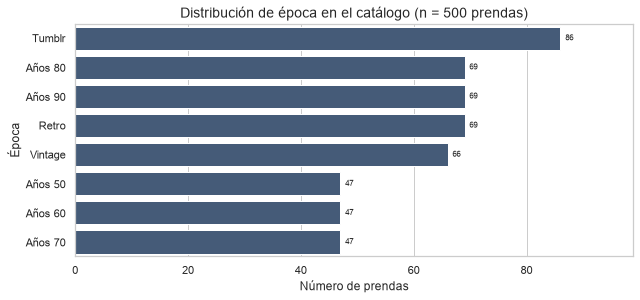

epoca: 8 categorías | mínimo 47 | máximo 86 (Tumblr)
          n
epoca      
Tumblr   86
Años 80  69
Años 90  69
Retro    69
Vintage  66
Años 50  47
Años 60  47
Años 70  47


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/a_distribucion_color.png


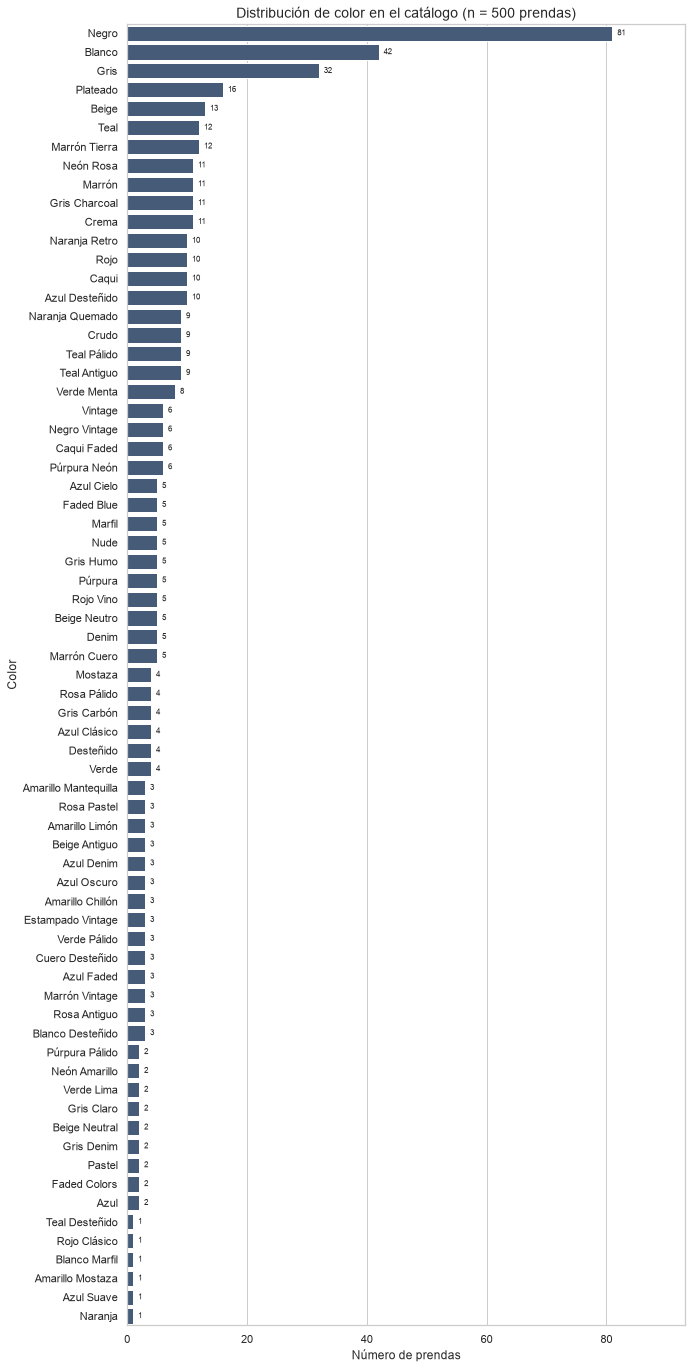

color: 69 categorías | mínimo 1 | máximo 81 (Negro)
Top 10
                n
color            
Negro          81
Blanco         42
Gris           32
Plateado       16
Beige          13
Teal           12
Marrón Tierra  12
Neón Rosa      11
Marrón         11
Gris Charcoal  11
Las 10 menos frecuentes
                  n
color              
Gris Denim        2
Pastel            2
Faded Colors      2
Azul              2
Teal Desteñido    1
Rojo Clásico      1
Blanco Marfil     1
Amarillo Mostaza  1
Azul Suave        1
Naranja           1
categorías con 3 prendas o menos: 29


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/a_distribucion_patron.png


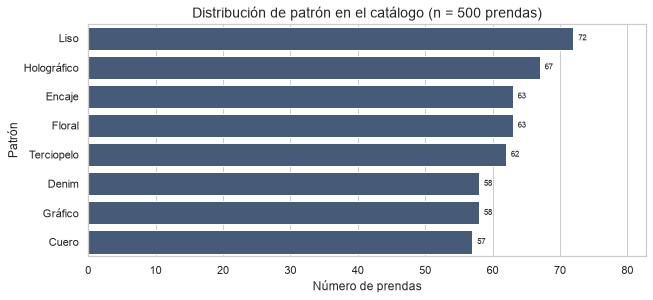

patron: 8 categorías | mínimo 57 | máximo 72 (Liso)
              n
patron         
Liso         72
Holográfico  67
Encaje       63
Floral       63
Terciopelo   62
Denim        58
Gráfico      58
Cuero        57


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/a_distribucion_estilo.png


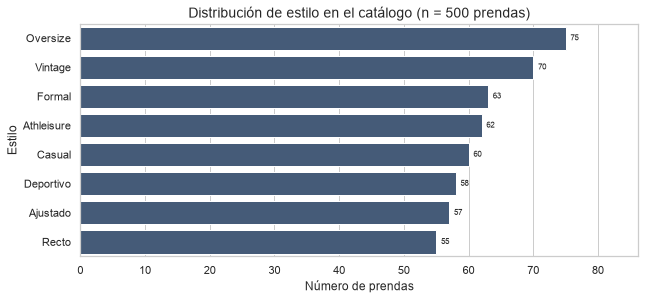

estilo: 8 categorías | mínimo 55 | máximo 75 (Oversize)
             n
estilo        
Oversize    75
Vintage     70
Formal      63
Athleisure  62
Casual      60
Deportivo   58
Ajustado    57
Recto       55


In [3]:
catalogo = datasets['prendas_base_500_mejorado']
print('prendas en catálogo:', len(catalogo))

for atributo in ATRIBUTOS:
    conteo = catalogo[atributo].value_counts()
    alto = max(4.2, 0.32 * len(conteo) + 1.4)
    fig, ax = plt.subplots(figsize=(10, alto))
    sns.barplot(x=conteo.values, y=conteo.index.astype(str), ax=ax, color='#3D5A80')
    ax.set_title(f'Distribución de {TITULOS[atributo].lower()} en el catálogo (n = {len(catalogo)} prendas)')
    ax.set_xlabel('Número de prendas')
    ax.set_ylabel(TITULOS[atributo])
    ax.set_xlim(0, conteo.max() * 1.15)
    for i, n in enumerate(conteo.values):
        ax.text(n + conteo.max() * 0.01, i, str(int(n)), va='center', fontsize=8)
    guardar_figura(fig, f'a_distribucion_{atributo}')
    print(f'{atributo}: {len(conteo)} categorías | mínimo {int(conteo.min())} | máximo {int(conteo.max())} ({conteo.idxmax()})')
    if len(conteo) <= 12:
        print(conteo.to_frame('n').to_string())
    else:
        print('Top 10')
        print(conteo.head(10).to_frame('n').to_string())
        print('Las 10 menos frecuentes')
        print(conteo.tail(10).to_frame('n').to_string())
        print('categorías con 3 prendas o menos:', int((conteo <= 3).sum()))


## 4. Tasa de compatibilidad por atributo

Una fila por prenda presente dentro del outfit, con la etiqueta `compatible` de ese outfit. La línea punteada es la tasa de ese formato. Las barras en terracota tienen n < 30.

filas en formato largo: 245,090
tasa de outfits: 0.75
tasa de piezas: 0.796
posicion
1    100000
2    100000
3     45090


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/b_tasa_epoca.png


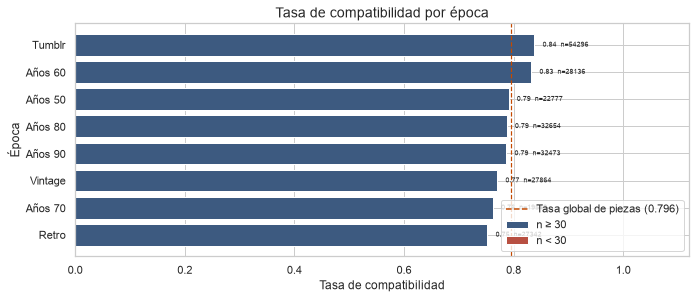

--- epoca: mínimo 0.752 (Retro) | máximo 0.838 (Tumblr) | categorías n<30: 0/8
             n  compatibles   tasa
epoca                             
Tumblr   54296        45491  0.838
Años 60  28136        23412  0.832
Años 50  22777        18012  0.791
Años 80  32654        25710  0.787
Años 90  32473        25544  0.787
Vintage  27864        21457  0.770
Años 70  19548        14900  0.762
Retro    27342        20564  0.752


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/b_tasa_color.png


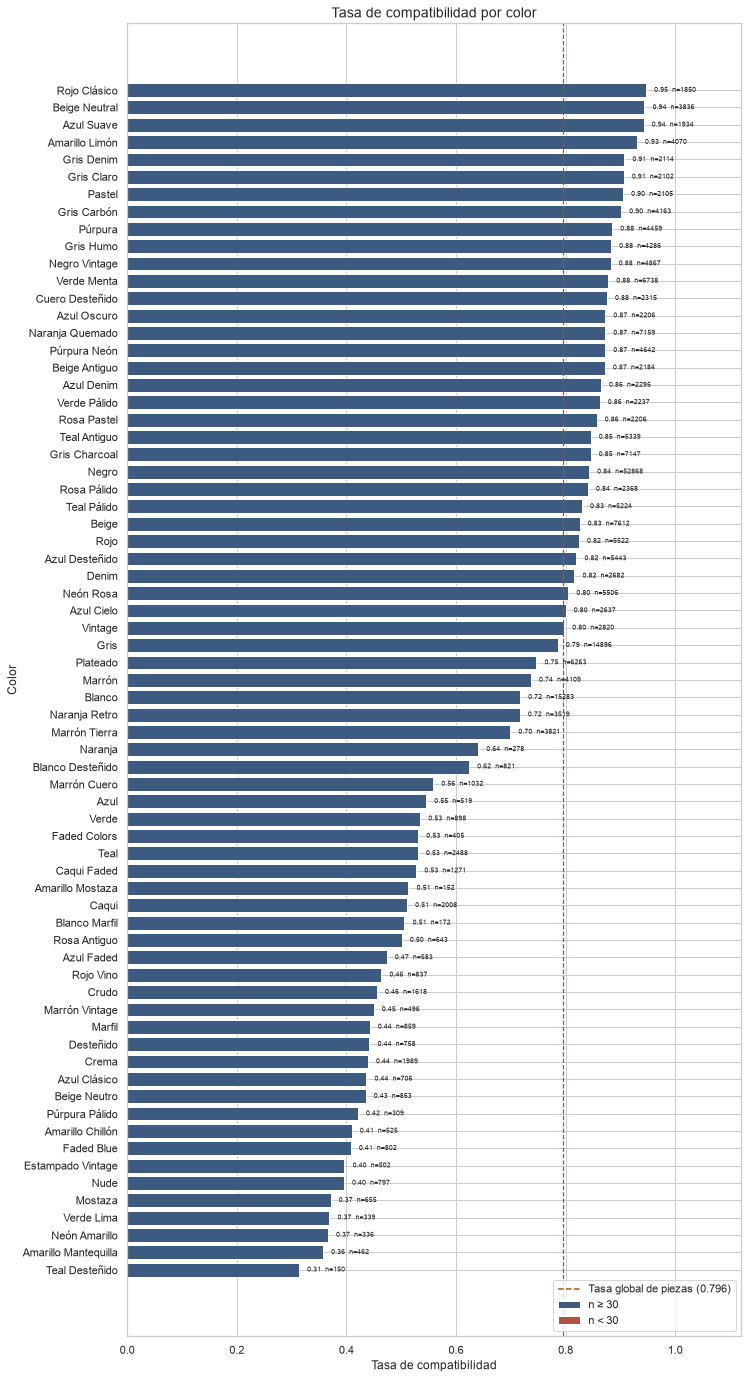

--- color: mínimo 0.313 (Teal Desteñido) | máximo 0.946 (Rojo Clásico) | categorías n<30: 0/69
                         n  compatibles   tasa
color                                         
Rojo Clásico          1850         1751  0.946
Beige Neutral         3836         3620  0.944
Azul Suave            1934         1822  0.942
Amarillo Limón        4070         3784  0.930
Gris Denim            2114         1917  0.907
Gris Claro            2102         1904  0.906
Pastel                2105         1904  0.905
Gris Carbón           4163         3751  0.901
Faded Blue             802          327  0.408
Estampado Vintage      502          199  0.396
Nude                   797          315  0.395
Mostaza                655          243  0.371
Verde Lima             339          125  0.369
Neón Amarillo          336          123  0.366
Amarillo Mantequilla   462          165  0.357
Teal Desteñido         150           47  0.313


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/b_tasa_patron.png


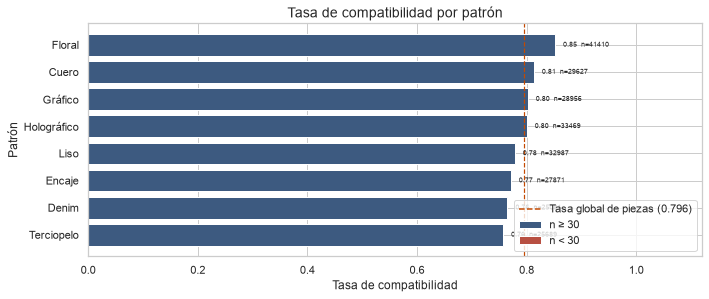

--- patron: mínimo 0.757 (Terciopelo) | máximo 0.851 (Floral) | categorías n<30: 0/8
                 n  compatibles   tasa
patron                                
Floral       41410        35260  0.851
Cuero        29627        24082  0.813
Gráfico      28956        23214  0.802
Holográfico  33469        26769  0.800
Liso         32987        25667  0.778
Encaje       27871        21482  0.771
Denim        25081        19177  0.765
Terciopelo   25689        19439  0.757


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/b_tasa_estilo.png


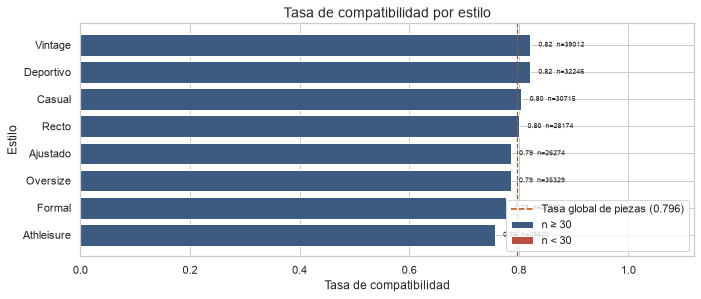

--- estilo: mínimo 0.756 (Athleisure) | máximo 0.821 (Vintage) | categorías n<30: 0/8
                n  compatibles   tasa
estilo                               
Vintage     39012        32023  0.821
Deportivo   32246        26465  0.821
Casual      30715        24719  0.805
Recto       28174        22564  0.801
Ajustado    26274        20642  0.786
Oversize    35329        27748  0.785
Formal      27720        21549  0.777
Athleisure  25620        19380  0.756


In [4]:
from matplotlib.patches import Patch

prendas_largo = a_formato_largo(outfits_unido, 'outfit_id')
tasa_outfit = float(outfits_unido['compatible'].mean())
tasa_piezas = float(prendas_largo['compatible'].mean())
print('filas en formato largo:', f'{len(prendas_largo):,}')
print('tasa de outfits:', round(tasa_outfit, 4))
print('tasa de piezas:', round(tasa_piezas, 4))
print(prendas_largo['posicion'].value_counts().sort_index().to_string())

for atributo in ATRIBUTOS:
    tabla = tabla_tasa(prendas_largo, atributo)
    plot_df = tabla.sort_values('tasa')
    y = np.arange(len(plot_df))
    colores = ['#B85042' if n < 30 else '#3D5A80' for n in plot_df['n']]
    alto = max(4.2, 0.32 * len(plot_df) + 1.6)
    fig, ax = plt.subplots(figsize=(11, alto))
    ax.barh(y, plot_df['tasa'], color=colores)
    ax.axvline(tasa_piezas, color='#C44900', ls='--', lw=1.2)
    ax.set_yticks(y)
    ax.set_yticklabels(plot_df.index.astype(str))
    ax.set_xlim(0, 1.12)
    ax.set_xlabel('Tasa de compatibilidad')
    ax.set_ylabel(TITULOS[atributo])
    ax.set_title(f'Tasa de compatibilidad por {TITULOS[atributo].lower()}')
    for i, (tasa, n) in enumerate(zip(plot_df['tasa'], plot_df['n'])):
        ax.text(min(tasa + 0.015, 1.0), i, f'{tasa:.2f}  n={int(n)}', va='center', fontsize=7)
    ax.legend(handles=[
        plt.Line2D([0], [0], color='#C44900', ls='--', label=f'Tasa global de piezas ({tasa_piezas:.3f})'),
        Patch(facecolor='#3D5A80', label='n ≥ 30'),
        Patch(facecolor='#B85042', label='n < 30'),
    ], loc='lower right')
    guardar_figura(fig, f'b_tasa_{atributo}')
    print(
        f"--- {atributo}: mínimo {tabla['tasa'].min():.3f} ({tabla['tasa'].idxmin()}) | "
        f"máximo {tabla['tasa'].max():.3f} ({tabla['tasa'].idxmax()}) | "
        f"categorías n<30: {int((tabla['n'] < 30).sum())}/{len(tabla)}"
    )
    visible = tabla if len(tabla) <= 12 else pd.concat([tabla.head(8), tabla.tail(8)])
    print(visible.assign(tasa=lambda d: d['tasa'].round(3)).to_string())


## 5. Pares prenda_1 × prenda_2

Tasa de `compatible` para época, estilo, patrón y color. En las matrices de 8×8 el asterisco marca n < 30. En color, la sombra gris marca n < 30: hay 69 niveles y la mayoría de los pares no llegan a ese n.

outfits con prenda_1 y prenda_2: 100,000
--- epoca: celdas 64 | n<30 0 | n>=30 64
pares n>=30 con tasa más alta
epoca_1 epoca_2    n  tasa
 Tumblr Años 60 9181 0.955
Años 80 Años 90 9201 0.949
Años 60  Tumblr 5621 0.924
Años 60   Retro 3829 0.921
Años 50 Años 50 1946 0.893
Años 50 Años 60 1888 0.889
pares n>=30 con tasa más baja
epoca_1 epoca_2   n  tasa
Años 60 Años 50 222   0.0
Años 70 Años 90 344   0.0
Años 70 Vintage 273   0.0
Años 70 Años 50 251   0.0
Años 70 Años 60 208   0.0
Años 70 Años 70 188   0.0


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/c_heatmap_epoca.png


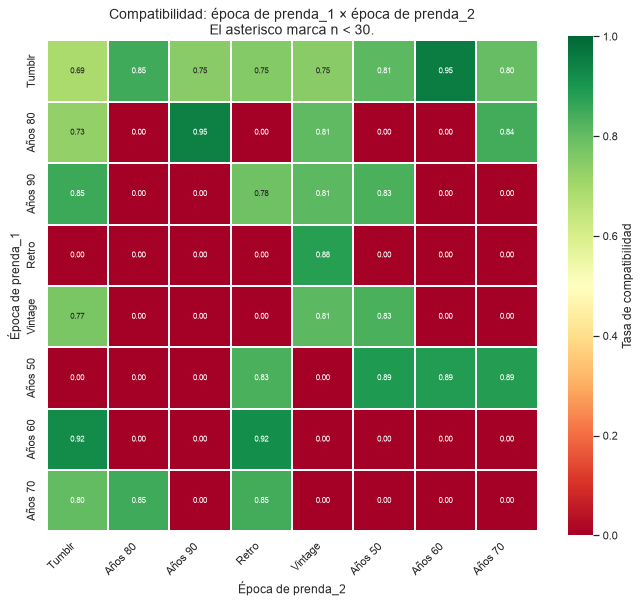

--- color: celdas 4761 | n<30 4594 | n>=30 167
pares n>=30 con tasa más alta
        color_1       color_2    n  tasa
     Gris Denim   Gris Carbón 1733 1.000
   Púrpura Neón         Denim 1764 1.000
        Vintage   Azul Oscuro 1706 1.000
  Beige Neutral Beige Antiguo 1729 1.000
Cuero Desteñido        Marrón 1759 0.999
         Pastel     Gris Humo 1682 0.999
pares n>=30 con tasa más baja
     color_1 color_2  n  tasa
  Azul Denim   Negro 30   0.0
 Rosa Pálido   Negro 36   0.0
       Denim   Negro 49   0.0
Marrón Cuero   Negro 41   0.0
   Desteñido   Negro 49   0.0
Verde Pálido   Negro 30   0.0


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/c_heatmap_color.png


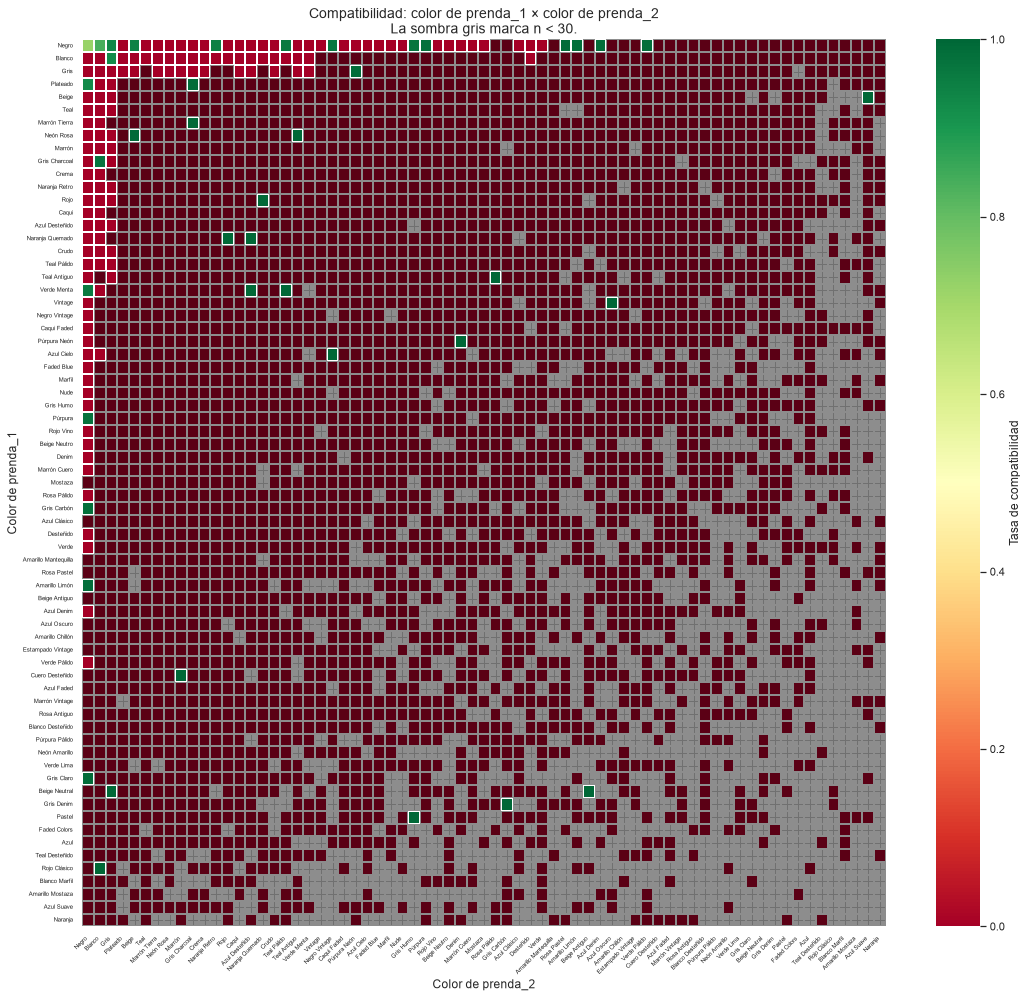

--- patron: celdas 64 | n<30 0 | n>=30 64
pares n>=30 con tasa más alta
   patron_1    patron_2    n  tasa
     Floral     Gráfico 5664 0.937
     Floral      Encaje 5579 0.935
      Cuero        Liso 5557 0.931
    Gráfico  Terciopelo 3816 0.907
 Terciopelo       Denim 3879 0.903
Holográfico Holográfico 3859 0.889
pares n>=30 con tasa más baja
patron_1    patron_2   n  tasa
 Gráfico        Liso 429   0.0
 Gráfico      Encaje 354   0.0
 Gráfico     Gráfico 331   0.0
   Cuero Holográfico 383   0.0
   Cuero      Encaje 339   0.0
   Cuero  Terciopelo 360   0.0


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/c_heatmap_patron.png


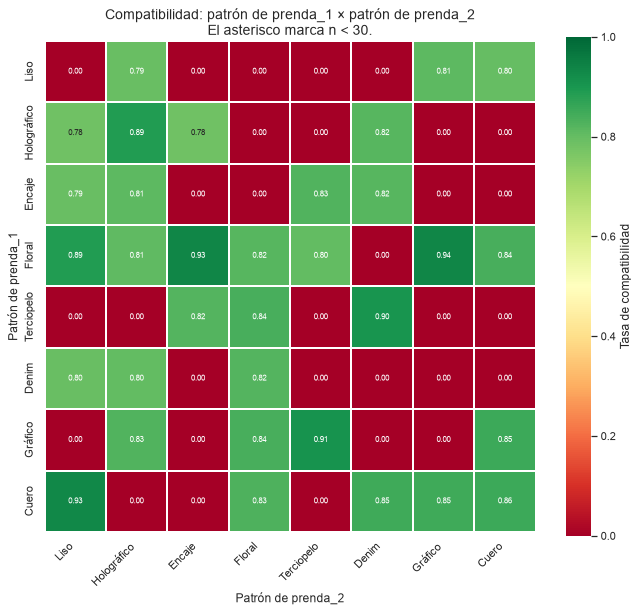

--- estilo: celdas 64 | n<30 0 | n>=30 64
pares n>=30 con tasa más alta
 estilo_1   estilo_2    n  tasa
    Recto  Deportivo 5592 0.939
  Vintage   Ajustado 5582 0.927
   Casual     Casual 3784 0.916
Deportivo Athleisure 3773 0.904
   Formal     Formal 3926 0.901
  Vintage     Casual 3755 0.895
pares n>=30 con tasa más baja
estilo_1   estilo_2   n  tasa
Ajustado     Casual 315   0.0
Ajustado Athleisure 348   0.0
Ajustado    Vintage 381   0.0
Ajustado  Deportivo 327   0.0
   Recto     Casual 354   0.0
   Recto      Recto 273   0.0


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/c_heatmap_estilo.png


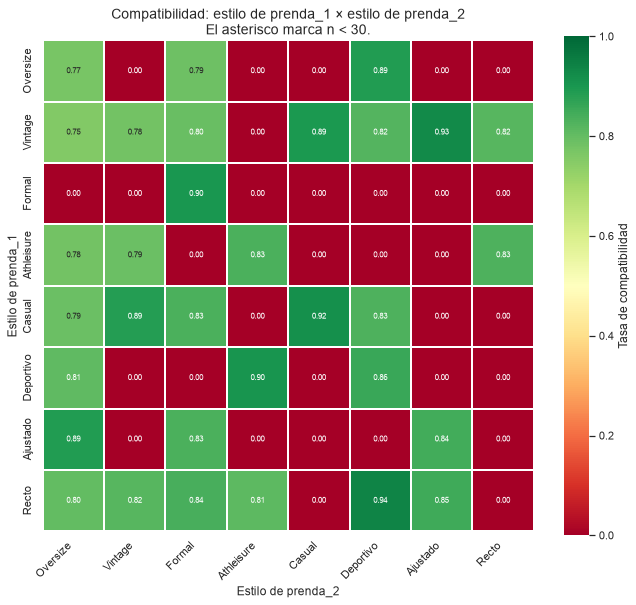

In [5]:
catalogo = datasets['prendas_base_500_mejorado']
pares = outfits_unido.loc[
    referencia_presente(outfits_unido['prenda_1']) & referencia_presente(outfits_unido['prenda_2'])
].copy()
print('outfits con prenda_1 y prenda_2:', f'{len(pares):,}')

for atributo in ATRIBUTOS:
    orden = catalogo[atributo].value_counts().index.tolist()
    conteo, tasa = resumen_pares(pares, atributo, orden)
    n_celdas = int(conteo.size)
    n_bajas = int((conteo < 30).sum().sum())
    print(f'--- {atributo}: celdas {n_celdas} | n<30 {n_bajas} | n>=30 {n_celdas - n_bajas}')

    planos = pd.DataFrame({'n': conteo.stack(), 'tasa': tasa.stack()}).reset_index()
    planos.columns = [f'{atributo}_1', f'{atributo}_2', 'n', 'tasa']
    suficientes = planos[planos['n'] >= 30].sort_values('tasa', ascending=False)
    print('pares n>=30 con tasa más alta')
    print(suficientes.head(6).round(3).to_string(index=False))
    print('pares n>=30 con tasa más baja')
    print(suficientes.tail(6).round(3).to_string(index=False))

    es_color = atributo == 'color'
    fig, ax = plt.subplots(figsize=(18, 16) if es_color else (11, 9))
    anotacion = None
    if not es_color:
        anotacion = np.empty(tasa.shape, dtype=object)
        for i in range(tasa.shape[0]):
            for j in range(tasa.shape[1]):
                n = int(conteo.iloc[i, j])
                valor = tasa.iloc[i, j]
                if pd.isna(valor):
                    anotacion[i, j] = '*'
                else:
                    anotacion[i, j] = f'{valor:.2f}' + ('*' if n < 30 else '')
    sns.heatmap(
        tasa, ax=ax, cmap='RdYlGn', vmin=0, vmax=1, square=True,
        linewidths=0.3, linecolor='white',
        annot=anotacion, fmt='', annot_kws={'size': 8},
        cbar_kws={'label': 'Tasa de compatibilidad'},
    )
    if es_color:
        n = conteo.shape[0]
        sombra = np.ma.masked_where(conteo.to_numpy() >= 30, np.ones((n, n)))
        ax.imshow(
            sombra, cmap='Greys', alpha=0.45, vmin=0, vmax=1,
            extent=(0, n, n, 0), origin='upper', aspect='auto', zorder=3,
        )
        ax.tick_params(axis='both', labelsize=6)
    ax.set_xlabel(f'{TITULOS[atributo]} de prenda_2')
    ax.set_ylabel(f'{TITULOS[atributo]} de prenda_1')
    detalle = 'La sombra gris marca n < 30.' if es_color else 'El asterisco marca n < 30.'
    ax.set_title(
        f'Compatibilidad: {TITULOS[atributo].lower()} de prenda_1 × {TITULOS[atributo].lower()} de prenda_2\n{detalle}'
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    guardar_figura(fig, f'c_heatmap_{atributo}')


## 6. Coincidencias dentro del outfit

`misma_epoca`, `mismo_estilo`, `mismo_patron` y `mismo_color` valen sí solo si todas las prendas presentes comparten ese atributo. La línea punteada es la tasa del train.

           grupo     n  tasa
 Misma época: sí  5685 0.433
 Misma época: no 94315 0.769
Mismo estilo: sí 10567 0.720
Mismo estilo: no 89433 0.754
Mismo patrón: sí  6357 0.509
Mismo patrón: no 93643 0.766
 Mismo color: sí  2099 0.444
 Mismo color: no 97901 0.757
       2 prendas 54910 0.545
       3 prendas 45090 1.000


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/d_coincidencias.png


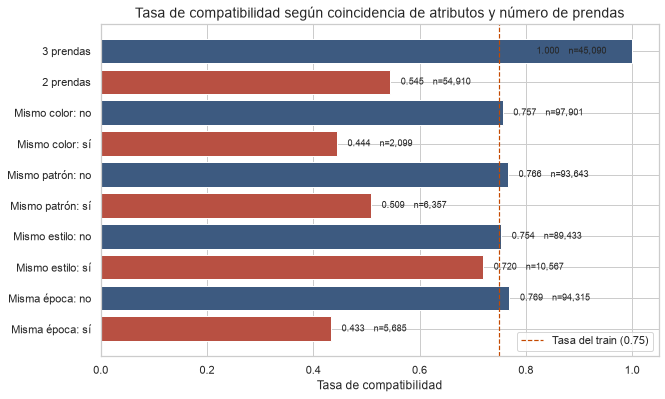

In [6]:
outfits_unido = agregar_coincidencias(outfits_unido)
resumen_coincidencias = tasas_grupo(outfits_unido)
print(resumen_coincidencias.assign(tasa=lambda d: d['tasa'].round(3)).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(resumen_coincidencias))
colores = ['#3D5A80' if t >= 0.75 else '#B85042' for t in resumen_coincidencias['tasa']]
ax.barh(y, resumen_coincidencias['tasa'], color=colores)
ax.axvline(0.75, color='#C44900', ls='--', lw=1.2, label='Tasa del train (0.75)')
ax.set_yticks(y)
ax.set_yticklabels(resumen_coincidencias['grupo'])
ax.set_xlim(0, 1.05)
ax.set_xlabel('Tasa de compatibilidad')
ax.set_title('Tasa de compatibilidad según coincidencia de atributos y número de prendas')
for i, (tasa, n) in enumerate(zip(resumen_coincidencias['tasa'], resumen_coincidencias['n'])):
    ax.text(min(tasa + 0.02, 0.82), i, f'{tasa:.3f}   n={n:,}', va='center', fontsize=9)
ax.legend(loc='lower right')
guardar_figura(fig, 'd_coincidencias')


## 7. Score y clase

Distribución de `score_compatibilidad` según `compatible`, y cuánto se separan las dos clases.

                n  media  mediana   desv  minimo  maximo
compatible                                              
0           25000  0.175     0.18  0.101     0.0    0.35
1           75000  0.850     0.85  0.087     0.7    1.00
correlación punto-biserial: r=0.955  p=0.00e+00
accuracy de score >= 0.5: 1.0
score mínimo en clase 1: 0.7
score máximo en clase 0: 0.35


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/e_score_por_clase.png


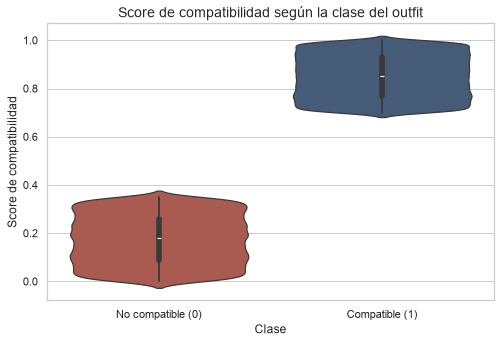

In [7]:
resumen_score = (outfits_unido.groupby('compatible')['score_compatibilidad']
                 .agg(n='size', media='mean', mediana='median', desv='std', minimo='min', maximo='max'))
print(resumen_score.round(3).to_string())
r, p = pointbiserialr(outfits_unido['compatible'], outfits_unido['score_compatibilidad'])
print(f'correlación punto-biserial: r={r:.3f}  p={p:.2e}')

umbral = (outfits_unido['score_compatibilidad'] >= 0.5).astype(int)
print('accuracy de score >= 0.5:', round(float((umbral == outfits_unido['compatible']).mean()), 4))
print('score mínimo en clase 1:', float(outfits_unido.loc[outfits_unido['compatible'].eq(1), 'score_compatibilidad'].min()))
print('score máximo en clase 0:', float(outfits_unido.loc[outfits_unido['compatible'].eq(0), 'score_compatibilidad'].max()))

fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(
    data=outfits_unido, x='compatible', y='score_compatibilidad',
    hue='compatible', inner='box', ax=ax,
    palette={0: '#B85042', 1: '#3D5A80'}, legend=False,
)
ax.set_xticks([0, 1])
ax.set_xticklabels(['No compatible (0)', 'Compatible (1)'])
ax.set_xlabel('Clase')
ax.set_ylabel('Score de compatibilidad')
ax.set_title('Score de compatibilidad según la clase del outfit')
guardar_figura(fig, 'e_score_por_clase')


## 8. Asociación con la etiqueta

Chi-cuadrado y V de Cramér. Época, color, patrón y estilo se miden por prenda, así que el mismo outfit se repite y el p-valor queda inflado. Las coincidencias y `n_prendas` se miden por outfit. La tabla queda ordenada por V de Cramér.

    variable unidad  niveles      n    chi2  gl         p  v_cramer  prop_esperados_menores_5
   n_prendas outfit        2 100000 27369.6   1  0.00e+00     0.523                       0.0
       color  pieza       69 245090 22204.7  68  0.00e+00     0.301                       0.0
 misma_epoca outfit        2 100000  3220.1   1  0.00e+00     0.179                       0.0
mismo_patron outfit        2 100000  2106.2   1  0.00e+00     0.145                       0.0
 mismo_color outfit        2 100000  1065.6   1 1.01e-233     0.103                       0.0
       epoca  pieza        8 245090  1424.6   7 1.84e-303     0.076                       0.0
      patron  pieza        8 245090  1416.5   7 1.02e-301     0.076                       0.0
      estilo  pieza        8 245090   636.3   7 3.78e-133     0.051                       0.0
mismo_estilo outfit        2 100000    57.7   1  3.05e-14     0.024                       0.0


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/f_cramer.png


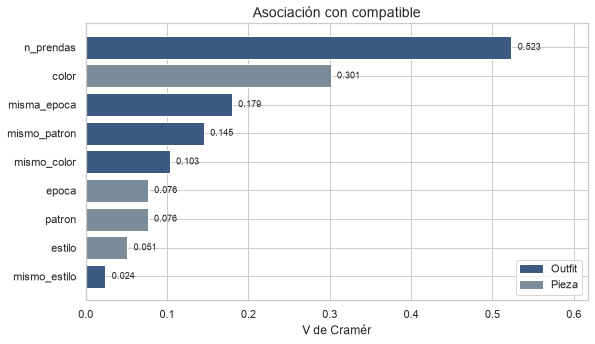

In [8]:
def asociacion(x, y, nombre, unidad):
    tabla = pd.crosstab(x, y)
    chi2, p_valor, gl, esperado = chi2_contingency(tabla)
    n = int(tabla.to_numpy().sum())
    filas, cols = tabla.shape
    v = np.sqrt(chi2 / (n * (min(filas, cols) - 1)))
    return {
        'variable': nombre,
        'unidad': unidad,
        'niveles': int(filas),
        'n': n,
        'chi2': chi2,
        'gl': int(gl),
        'p': p_valor,
        'v_cramer': v,
        'prop_esperados_menores_5': float((esperado < 5).mean()),
    }

filas = []
for atributo in ATRIBUTOS:
    filas.append(asociacion(prendas_largo[atributo], prendas_largo['compatible'], atributo, 'pieza'))
for columna in ['misma_epoca', 'mismo_estilo', 'mismo_patron', 'mismo_color', 'n_prendas']:
    filas.append(asociacion(outfits_unido[columna], outfits_unido['compatible'], columna, 'outfit'))

asociaciones = pd.DataFrame(filas).sort_values('v_cramer', ascending=False)
visible = asociaciones.copy()
visible['chi2'] = visible['chi2'].round(1)
visible['v_cramer'] = visible['v_cramer'].round(3)
visible['p'] = visible['p'].map(lambda valor: f'{valor:.2e}')
visible['prop_esperados_menores_5'] = visible['prop_esperados_menores_5'].round(3)
print(visible.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
orden = asociaciones.sort_values('v_cramer')
colores = ['#3D5A80' if unidad == 'outfit' else '#7A8B99' for unidad in orden['unidad']]
ax.barh(orden['variable'], orden['v_cramer'], color=colores)
ax.set_xlabel('V de Cramér')
ax.set_xlim(0, orden['v_cramer'].max() * 1.18)
ax.set_title('Asociación con compatible')
for i, valor in enumerate(orden['v_cramer']):
    ax.text(valor + 0.008, i, f'{valor:.3f}', va='center', fontsize=9)
ax.legend(handles=[
    plt.Rectangle((0, 0), 1, 1, color='#3D5A80', label='Outfit'),
    plt.Rectangle((0, 0), 1, 1, color='#7A8B99', label='Pieza'),
], loc='lower right')
guardar_figura(fig, 'f_cramer')


## 9. Reglas simples

Accuracy de predecir `compatible = 1` con `misma_epoca`, con `misma_epoca` y `mismo_estilo`, y con el baseline de predecir siempre 1. También se mide `n_prendas = 3`, que en la sección 6 separa por completo a los outfits compatibles.

                     regla  accuracy  predice_1  tasa_real_si_predice_1  tasa_real_si_predice_0
       Baseline: siempre 1    0.7500     100000                   0.750                     NaN
               misma_epoca    0.2424       5685                   0.433                   0.769
misma_epoca y mismo_estilo    0.2463        373                   0.000                   0.753
             n_prendas = 3    0.7009      45090                   1.000                   0.545


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/g_reglas.png


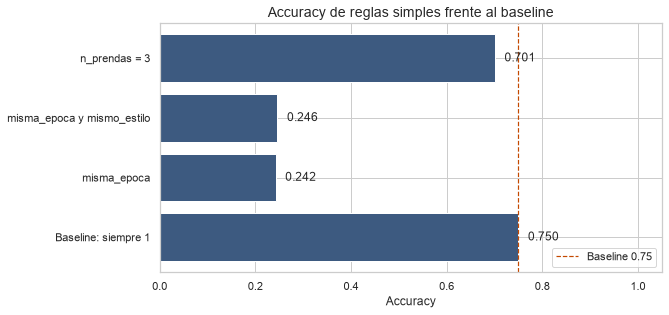

In [9]:
y = outfits_unido['compatible'].astype(int).to_numpy()
reglas = {
    'Baseline: siempre 1': np.ones(len(y), dtype=int),
    'misma_epoca': outfits_unido['misma_epoca'].astype(int).to_numpy(),
    'misma_epoca y mismo_estilo': (outfits_unido['misma_epoca'] & outfits_unido['mismo_estilo']).astype(int).to_numpy(),
    'n_prendas = 3': outfits_unido['n_prendas'].eq(3).astype(int).to_numpy(),
}

filas = []
for nombre, pred in reglas.items():
    filas.append({
        'regla': nombre,
        'accuracy': float((pred == y).mean()),
        'predice_1': int(pred.sum()),
        'tasa_real_si_predice_1': float(y[pred == 1].mean()) if pred.any() else np.nan,
        'tasa_real_si_predice_0': float(y[pred == 0].mean()) if (pred == 0).any() else np.nan,
    })
resumen_reglas = pd.DataFrame(filas)
print(resumen_reglas.assign(
    accuracy=lambda d: d['accuracy'].round(4),
    tasa_real_si_predice_1=lambda d: d['tasa_real_si_predice_1'].round(3),
    tasa_real_si_predice_0=lambda d: d['tasa_real_si_predice_0'].round(3),
).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(resumen_reglas['regla'], resumen_reglas['accuracy'], color='#3D5A80')
ax.axvline(0.75, color='#C44900', ls='--', lw=1.2, label='Baseline 0.75')
ax.set_xlim(0, 1.05)
ax.set_xlabel('Accuracy')
ax.set_title('Accuracy de reglas simples frente al baseline')
for i, acc in enumerate(resumen_reglas['accuracy']):
    ax.text(acc + 0.02, i, f'{acc:.3f}', va='center')
ax.legend(loc='lower right')
guardar_figura(fig, 'g_reglas')


## 10. Test de 30 casos

Se repiten la tasa por atributo y las coincidencias. Con 30 outfits todas las categorías quedan con n < 30, así que el color se deja en tabla y no en gráfico. Los puntos azules son la tasa del train.

test: 30 outfits | tasa 0.5 | train 0.75
referencias sin catálogo: 0
n_prendas
2    21
3     9
piezas en formato largo: 69 | tasa piezas test 0.565 | train 0.796
           grupo  n_train  tasa_train  n_test  tasa_test
 Misma época: sí     5685       0.433       2      0.000
 Misma época: no    94315       0.769      28      0.536
Mismo estilo: sí    10567       0.720       4      0.750
Mismo estilo: no    89433       0.754      26      0.462
Mismo patrón: sí     6357       0.509       1      0.000
Mismo patrón: no    93643       0.766      29      0.517
 Mismo color: sí     2099       0.444       0        NaN
 Mismo color: no    97901       0.757      30      0.500
       2 prendas    54910       0.545      21      0.286
       3 prendas    45090       1.000       9      1.000


GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/h_coincidencias_train_test.png


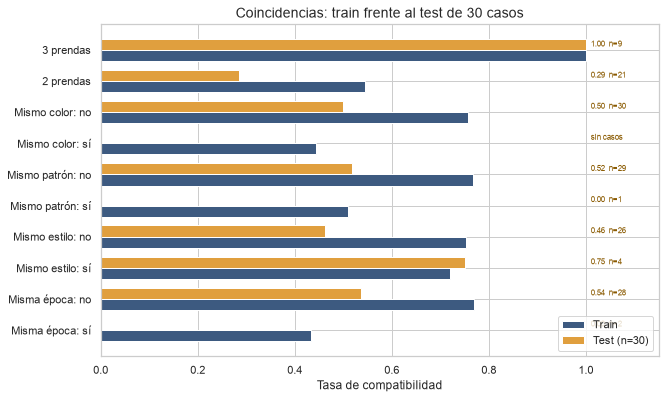

--- epoca: categorías en el test 8 | con n<30: 8
         n_test  tasa_test  n_train  tasa_train
epoca                                          
Retro        13      0.538    27342       0.752
Años 70      12      0.583    19548       0.762
Años 80      11      0.545    32654       0.787
Años 60       8      0.500    28136       0.832
Tumblr        8      0.625    54296       0.838
Años 50       6      0.500    22777       0.791
Años 90       6      0.667    32473       0.787
Vintage       5      0.600    27864       0.770
--- estilo: categorías en el test 8 | con n<30: 8
            n_test  tasa_test  n_train  tasa_train
estilo                                            
Vintage         12      0.583    39012       0.821
Athleisure      12      0.583    25620       0.756
Recto            9      0.889    28174       0.801
Oversize         8      0.500    35329       0.785
Deportivo        8      0.500    32246       0.821
Casual           7      0.429    30715       0.805
Ajustado     

GUARDADO C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_eda/h_tasas_test_epoca_estilo_patron.png


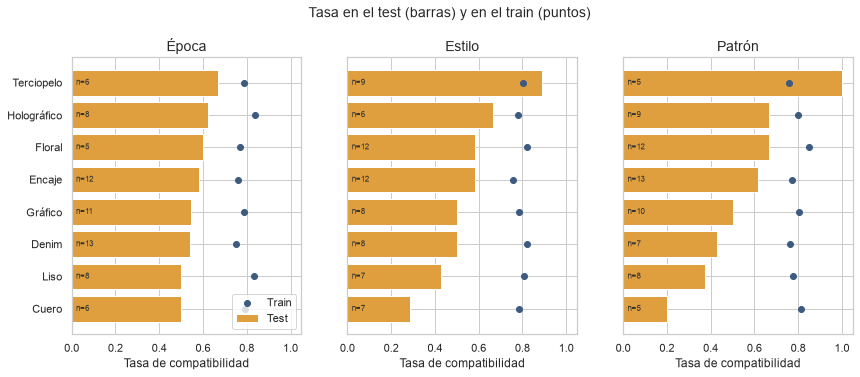

--- color: categorías en el test 36 | con una sola pieza: 22
                 n_test  tasa_test  n_train  tasa_train
color                                                  
Negro                 8      0.375    52868       0.843
Naranja Quemado       5      0.800     7159       0.872
Marrón Tierra         4      0.750     3821       0.699
Rojo                  4      0.750     5522       0.824
Gris Charcoal         3      1.000     7147       0.845
Teal Pálido           3      0.667     5224       0.830
Azul Desteñido        3      0.667     5443       0.819
Blanco                3      0.667    15283       0.717
Beige                 3      0.667     7612       0.825
Marrón                3      0.333     4109       0.736
Rojo Clásico          2      1.000     1850       0.946
Verde Menta           2      0.500     6738       0.877


In [10]:
test_unido, prendas_test_sin_catalogo = unir_con_catalogo(
    datasets['test_30_predefinido'], datasets['prendas_base_500_mejorado']
)
test_unido = agregar_coincidencias(test_unido)
test_largo = a_formato_largo(test_unido, 'test_id')

print('test:', len(test_unido), 'outfits | tasa', round(float(test_unido['compatible'].mean()), 3),
      '| train', round(float(outfits_unido['compatible'].mean()), 3))
print('referencias sin catálogo:', int(len(prendas_test_sin_catalogo)))
print(test_unido['n_prendas'].value_counts().sort_index().rename('n').to_string())
print('piezas en formato largo:', len(test_largo),
      '| tasa piezas test', round(float(test_largo['compatible'].mean()), 3),
      '| train', round(float(prendas_largo['compatible'].mean()), 3))

comp_d = tasas_grupo(outfits_unido).merge(tasas_grupo(test_unido), on='grupo', suffixes=('_train', '_test'))
print(comp_d.assign(
    tasa_train=lambda d: d['tasa_train'].round(3),
    tasa_test=lambda d: d['tasa_test'].round(3),
).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(comp_d))
ax.barh(y - 0.18, comp_d['tasa_train'], height=0.36, color='#3D5A80', label='Train')
ax.barh(y + 0.18, comp_d['tasa_test'], height=0.36, color='#E09F3E', label='Test (n=30)')
ax.set_yticks(y)
ax.set_yticklabels(comp_d['grupo'])
ax.set_xlim(0, 1.15)
ax.set_xlabel('Tasa de compatibilidad')
ax.set_title('Coincidencias: train frente al test de 30 casos')
for i, (tasa, n) in enumerate(zip(comp_d['tasa_test'], comp_d['n_test'])):
    texto = 'sin casos' if n == 0 or pd.isna(tasa) else f'{tasa:.2f}  n={int(n)}'
    ax.text(1.01, i + 0.18, texto, va='center', fontsize=8, color='#8A5A00')
ax.legend(loc='lower right')
guardar_figura(fig, 'h_coincidencias_train_test')

fig, ejes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
for ax, atributo in zip(ejes, ['epoca', 'estilo', 'patron']):
    train = tabla_tasa(prendas_largo, atributo)[['n', 'tasa']].rename(columns={'n': 'n_train', 'tasa': 'tasa_train'})
    test = tabla_tasa(test_largo, atributo)[['n', 'tasa']].rename(columns={'n': 'n_test', 'tasa': 'tasa_test'})
    comp = test.join(train, how='left').sort_values('tasa_test')
    print(f'--- {atributo}: categorías en el test {len(comp)} | con n<30: {int((comp.n_test < 30).sum())}')
    print(comp.sort_values('n_test', ascending=False).assign(
        tasa_test=lambda d: d['tasa_test'].round(3),
        tasa_train=lambda d: d['tasa_train'].round(3),
    ).to_string())
    y = np.arange(len(comp))
    ax.barh(y, comp['tasa_test'], color='#E09F3E', label='Test')
    ax.scatter(comp['tasa_train'], y, color='#3D5A80', zorder=3, label='Train')
    ax.set_yticks(y)
    ax.set_yticklabels(comp.index.astype(str))
    ax.set_xlim(0, 1.05)
    ax.set_xlabel('Tasa de compatibilidad')
    ax.set_title(TITULOS[atributo])
    for i, n in enumerate(comp['n_test']):
        ax.text(0.02, i, f'n={int(n)}', va='center', fontsize=8, color='#333333')
ejes[0].legend(loc='lower right')
fig.suptitle('Tasa en el test (barras) y en el train (puntos)', y=1.02)
guardar_figura(fig, 'h_tasas_test_epoca_estilo_patron')

train_color = tabla_tasa(prendas_largo, 'color')[['n', 'tasa']].rename(columns={'n': 'n_train', 'tasa': 'tasa_train'})
test_color = tabla_tasa(test_largo, 'color')[['n', 'tasa']].rename(columns={'n': 'n_test', 'tasa': 'tasa_test'})
comp_color = test_color.join(train_color, how='left').sort_values(['n_test', 'tasa_test'], ascending=False)
print(f'--- color: categorías en el test {len(comp_color)} | con una sola pieza: {int((comp_color.n_test == 1).sum())}')
print(comp_color.head(12).assign(
    tasa_test=lambda d: d['tasa_test'].round(3),
    tasa_train=lambda d: d['tasa_train'].round(3),
).to_string())


## 11. Exportar

`/content/outfits_unido.csv` incluye los atributos de cada prenda, `n_prendas` y las cuatro coincidencias. Las figuras quedan en `/content/figuras/`.

In [11]:
ruta = ROOT / 'data' / 'processed' / 'hito2' / 'outfits_unido.csv'
ruta.parent.mkdir(parents=True, exist_ok=True)
outfits_unido.to_csv(ruta, index=False)
print('filas', f'{len(outfits_unido):,}', '| columnas', outfits_unido.shape[1], '| MB', round(os.path.getsize(ruta) / 1024 / 1024, 2))
print('columnas:', list(outfits_unido.columns))
print('figuras:')
for nombre in sorted(os.listdir(CARPETA_FIGURAS)):
    print(' ', nombre)


filas 100,000 | columnas 23 | MB 13.71
columnas: ['outfit_id', 'prenda_1', 'prenda_2', 'prenda_3', 'compatible', 'score_compatibilidad', 'epoca_1', 'color_1', 'patron_1', 'estilo_1', 'epoca_2', 'color_2', 'patron_2', 'estilo_2', 'epoca_3', 'color_3', 'patron_3', 'estilo_3', 'n_prendas', 'misma_epoca', 'mismo_estilo', 'mismo_patron', 'mismo_color']
figuras:
  a_distribucion_color.png
  a_distribucion_epoca.png
  a_distribucion_estilo.png
  a_distribucion_patron.png
  b_tasa_color.png
  b_tasa_epoca.png
  b_tasa_estilo.png
  b_tasa_patron.png
  c_heatmap_color.png
  c_heatmap_epoca.png
  c_heatmap_estilo.png
  c_heatmap_patron.png
  d_coincidencias.png
  e_score_por_clase.png
  f_cramer.png
  g_reglas.png
  h_coincidencias_train_test.png
  h_tasas_test_epoca_estilo_patron.png
